# Manhattan results summary

A visual walkthrough of the results in `results/manhattan/`, loaded directly from the
committed JSON/PNG files (nothing here is re-run). For methodology, data pipeline, bug
fixes, and experiment configuration, see the repository [README](../README.md).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RESULTS = Path("../results/manhattan")

def load(name):
    with open(RESULTS / name) as f:
        return json.load(f)

## Experiment I: mode/duration prediction

Single-trip prediction against real eval trips: each row's real profile, desire, and time
are passed to the agent, which predicts a mode/duration pair.

In [2]:
exp1 = load("exp1_validation_summary.json")
exp1_results = load("exp1_test_1000.json")

summary = pd.DataFrame({
    "mode KLD": [exp1["aggregate"]["mode"]["kld"], exp1["trivial_baseline"]["mode"]["kld"]],
    "mode MAE": [exp1["aggregate"]["mode"]["mae"], exp1["trivial_baseline"]["mode"]["mae"]],
    "duration KLD": [exp1["aggregate"]["duration"]["kld"], exp1["trivial_baseline"]["duration"]["kld"]],
    "duration MAE": [exp1["aggregate"]["duration"]["mae"], exp1["trivial_baseline"]["duration"]["mae"]],
}, index=["Preference Chain", "Trivial baseline (always majority class)"])
print(f"n = {exp1['n_rows']} rows")
summary

n = 1000 rows


,mode KLD,mode MAE,duration KLD,duration MAE
Preference Chain,0.061661,0.025429,0.122495,0.037429
Trivial baseline (always majority class),12.770018,0.177429,15.140482,0.208571


In [3]:
sub = exp1["paper_metric_per_subgroup"]
display(Markdown(f"Paper's own per-subgroup-averaged metric: **overall_kl={sub['overall_kl']:.3f}**, "
                  f"**overall_mae={sub['overall_mae']:.3f}**"))

Paper's own per-subgroup-averaged metric: **overall_kl=0.392**, **overall_mae=0.055**

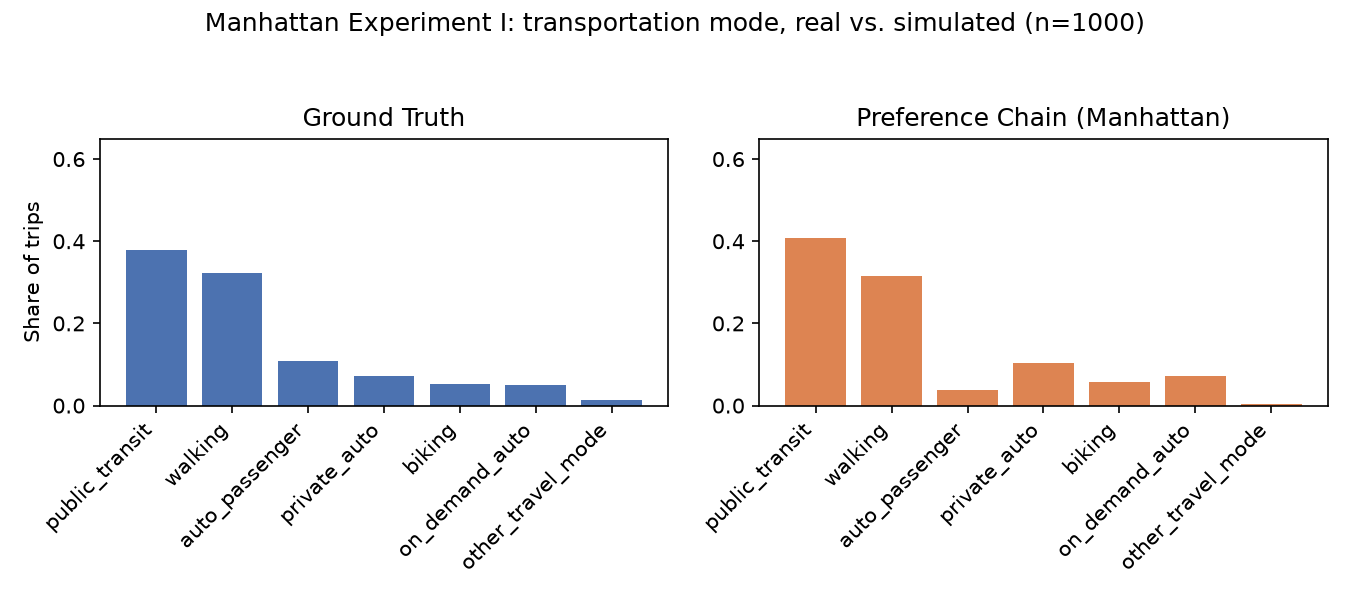

In [4]:
display(Image(filename=str(RESULTS / "exp1_mode_distribution.png")))

### One real example: input and output

Eval row index 0 of the deterministic 1000-row sample (`random_state=42`), real values from
`data/eval/replica-manhattan_trips_eval_max60_1000.csv`, matched by position to
`exp1_test_1000.json[0]`.

In [5]:
example_profile = {
    "age_group": "25-34", "income_group": "$50k-$100k", "employment_status": "employed",
    "household_size": 1, "available_vehicles": "zero", "education": "advanced_degree",
}
example_desire = "recreation"
example_time = "11:00"
example_distance = "0.9 miles"

prompt_text = f"""You are {example_profile}, tasked with simulating realistic transportation behavior based on reference data from people with similar profiles.

Current Time: {example_time}
Current Desire: {example_desire}
Current memory: ['Today is a normal weekday']
Target Distance: {example_distance}
Available Mode Choices : ['walking', 'biking', 'auto_passenger','public_transit','private_auto', 'on_demand_auto','other_travel_mode']
Available Duration Choices : ['0-10','10-20','20-30', '30-40', '40-50', '50-60']

Context: This is the reference behavior of people with similar profiles in Manhattan, New
York in a normal workday, computed from a graph-based prior model. Higher prior_weight
means more likely to be chosen by people with similar profile.
Reference choices with their prior probability (treat these as a starting point, not a
fixed answer):
[omitted here: this needs a live call to the local embedding server against the cached
reference graph. See scripts/show_real_prompt.py to reproduce exactly.]

What transportation mode and duration minutes do you prefer?

Note:
- Output your reason and preference weight of different choices
- The sum of all weights should equal 1.
- Start from the prior_weight values above, then adjust them based on your profile."""

display(Markdown(f"```\n{prompt_text}\n```"))

```
You are {'age_group': '25-34', 'income_group': '$50k-$100k', 'employment_status': 'employed', 'household_size': 1, 'available_vehicles': 'zero', 'education': 'advanced_degree'}, tasked with simulating realistic transportation behavior based on reference data from people with similar profiles.

Current Time: 11:00
Current Desire: recreation
Current memory: ['Today is a normal weekday']
Target Distance: 0.9 miles
Available Mode Choices : ['walking', 'biking', 'auto_passenger','public_transit','private_auto', 'on_demand_auto','other_travel_mode']
Available Duration Choices : ['0-10','10-20','20-30', '30-40', '40-50', '50-60']

Context: This is the reference behavior of people with similar profiles in Manhattan, New
York in a normal workday, computed from a graph-based prior model. Higher prior_weight
means more likely to be chosen by people with similar profile.
Reference choices with their prior probability (treat these as a starting point, not a
fixed answer):
[omitted here: this needs a live call to the local embedding server against the cached
reference graph. See scripts/show_real_prompt.py to reproduce exactly.]

What transportation mode and duration minutes do you prefer?

Note:
- Output your reason and preference weight of different choices
- The sum of all weights should equal 1.
- Start from the prior_weight values above, then adjust them based on your profile.
```

The real row's true answer and the LLM's actual response to this exact prompt:

In [6]:
example_result = exp1_results[0]
display(Markdown(
    f"- true: **{example_result['true_mode']}**, {example_result['true_duration']} min\n"
    f"- predicted: **{example_result['predicted_mode']}**, {example_result['predicted_duration']} min"
))
pd.DataFrame(json.loads(example_result["choice_weights"]))

- true: **walking**, 10-20 min
- predicted: **walking**, 10-20 min

,primary_mode,duration_minutes,weight
0,walking,10-20,0.450
1,public_transit,10-20,0.250
2,public_transit,20-30,0.150
3,biking,20-30,0.075
4,private_auto,10-20,0.075


### Discriminative power per mode

For each mode, does the graph's `choice_weight` for that mode actually predict whether it
was the real answer? AUC of 0.5 means no, the weight carries no signal for that mode.

In [7]:
disc = load("exp1_discriminative_power.json")
disc_df = pd.DataFrame(disc).T[["n_pos", "n_neg", "auc_discriminative_power", "p_value"]]
disc_df.sort_values("auc_discriminative_power", ascending=False)

,n_pos,n_neg,auc_discriminative_power,p_value
private_auto,72.0,928.0,0.794772,8.726646e-19
walking,323.0,677.0,0.760398,4.863435e-41
public_transit,379.0,621.0,0.672029,2.806136e-20
on_demand_auto,51.0,949.0,0.620447,7.699022e-04
auto_passenger,109.0,891.0,0.614962,6.357163e-06
other_travel_mode,14.0,986.0,0.549008,5.232095e-02
biking,52.0,948.0,0.495050,5.494939e-01


## Experiment II: full synthetic population

1000 synthetic agents, each with an LLM-generated full-day activity schedule, routed and
compared against real Manhattan trip data across several independent dimensions.

In [8]:
exp2 = load("exp2_modeshare_validation.json")
display(Markdown(
    f"- **{exp2['n_agents']}** agents, **{exp2['n_trips']}** trips, "
    f"**{exp2['stops_per_agent']['mean']:.1f}** stops/agent on average "
    f"(median {exp2['stops_per_agent']['median']:.0f})\n"
    f"- mode-share **KLD={exp2['mode']['kld']:.3f}**, MAE={exp2['mode']['mae']:.3f}\n"
    f"- duration **KLD={exp2['duration']['kld']:.3f}**, MAE={exp2['duration']['mae']:.3f}"
))

- **1000** agents, **8278** trips, **8.3** stops/agent on average (median 8)
- mode-share **KLD=0.039**, MAE=0.019
- duration **KLD=0.127**, MAE=0.025

In [9]:
mode_df = pd.DataFrame({
    "real": exp2["mode"]["real_%"],
    "simulated": exp2["mode"]["sim_%"],
}).fillna(0).sort_values("real", ascending=False)
mode_df

,real,simulated
public_transit,0.379,0.422
walking,0.323,0.365
auto_passenger,0.109,0.066
private_auto,0.072,0.080
biking,0.052,0.032
on_demand_auto,0.051,0.022
other_travel_mode,0.014,0.009
home,0.000,0.003
stay,0.000,0.000
stay_at_home,0.000,0.000


### One real example: a full synthetic agent

Agent index 10 of `exp2_agents_1000.json`. The profile itself is also generated by the
pipeline (`profile=None` triggers `ProfileGeneratorTool`, calibrated against real
demographics), not an input pulled from real data the way Experiment I's eval rows are.

In [10]:
agents = load("exp2_agents_1000.json")
example_agent = agents[10]
display(Markdown(f"```\n{json.loads(example_agent['profile'])}\n```"))
display(Markdown(f"Home: {example_agent['home']['coordinates']}"))

schedule_df = pd.DataFrame([
    {
        "start_time": s["start_time"],
        "desire": s["desire"],
        "mode": s["transportation"]["mode"],
        "duration": s["transportation"]["duration"],
        "destination": s["destination"]["name"],
        "distance_km": round(s["destination"]["distance_km"], 2),
    }
    for s in example_agent["schedule"]
])
schedule_df

```
{'name': 'Steven Humphrey', 'city': 'Manhattan, New York', 'age': 29, 'gender': 'male', 'employment_status': 'employed', 'education': 'bachelors_degree', 'household_size': 1, 'household_income': '150k+', 'available_vehicles': 1}
```

Home: [40.799487988629856, -73.967732864286]

,start_time,desire,mode,duration,destination,distance_km
0,09:00,shop,public_transit,20-30,Department Stores,1.51
1,10:00,work,public_transit,30-40,Barneys New York Inc.,3.88
2,14:00,eat,on_demand_auto,0-10,Full-Service Restaurants,0.38
3,16:00,social,walking,10-20,United Dominion Realty Trust,0.51
4,17:30,home,walking,0-10,home,0.00


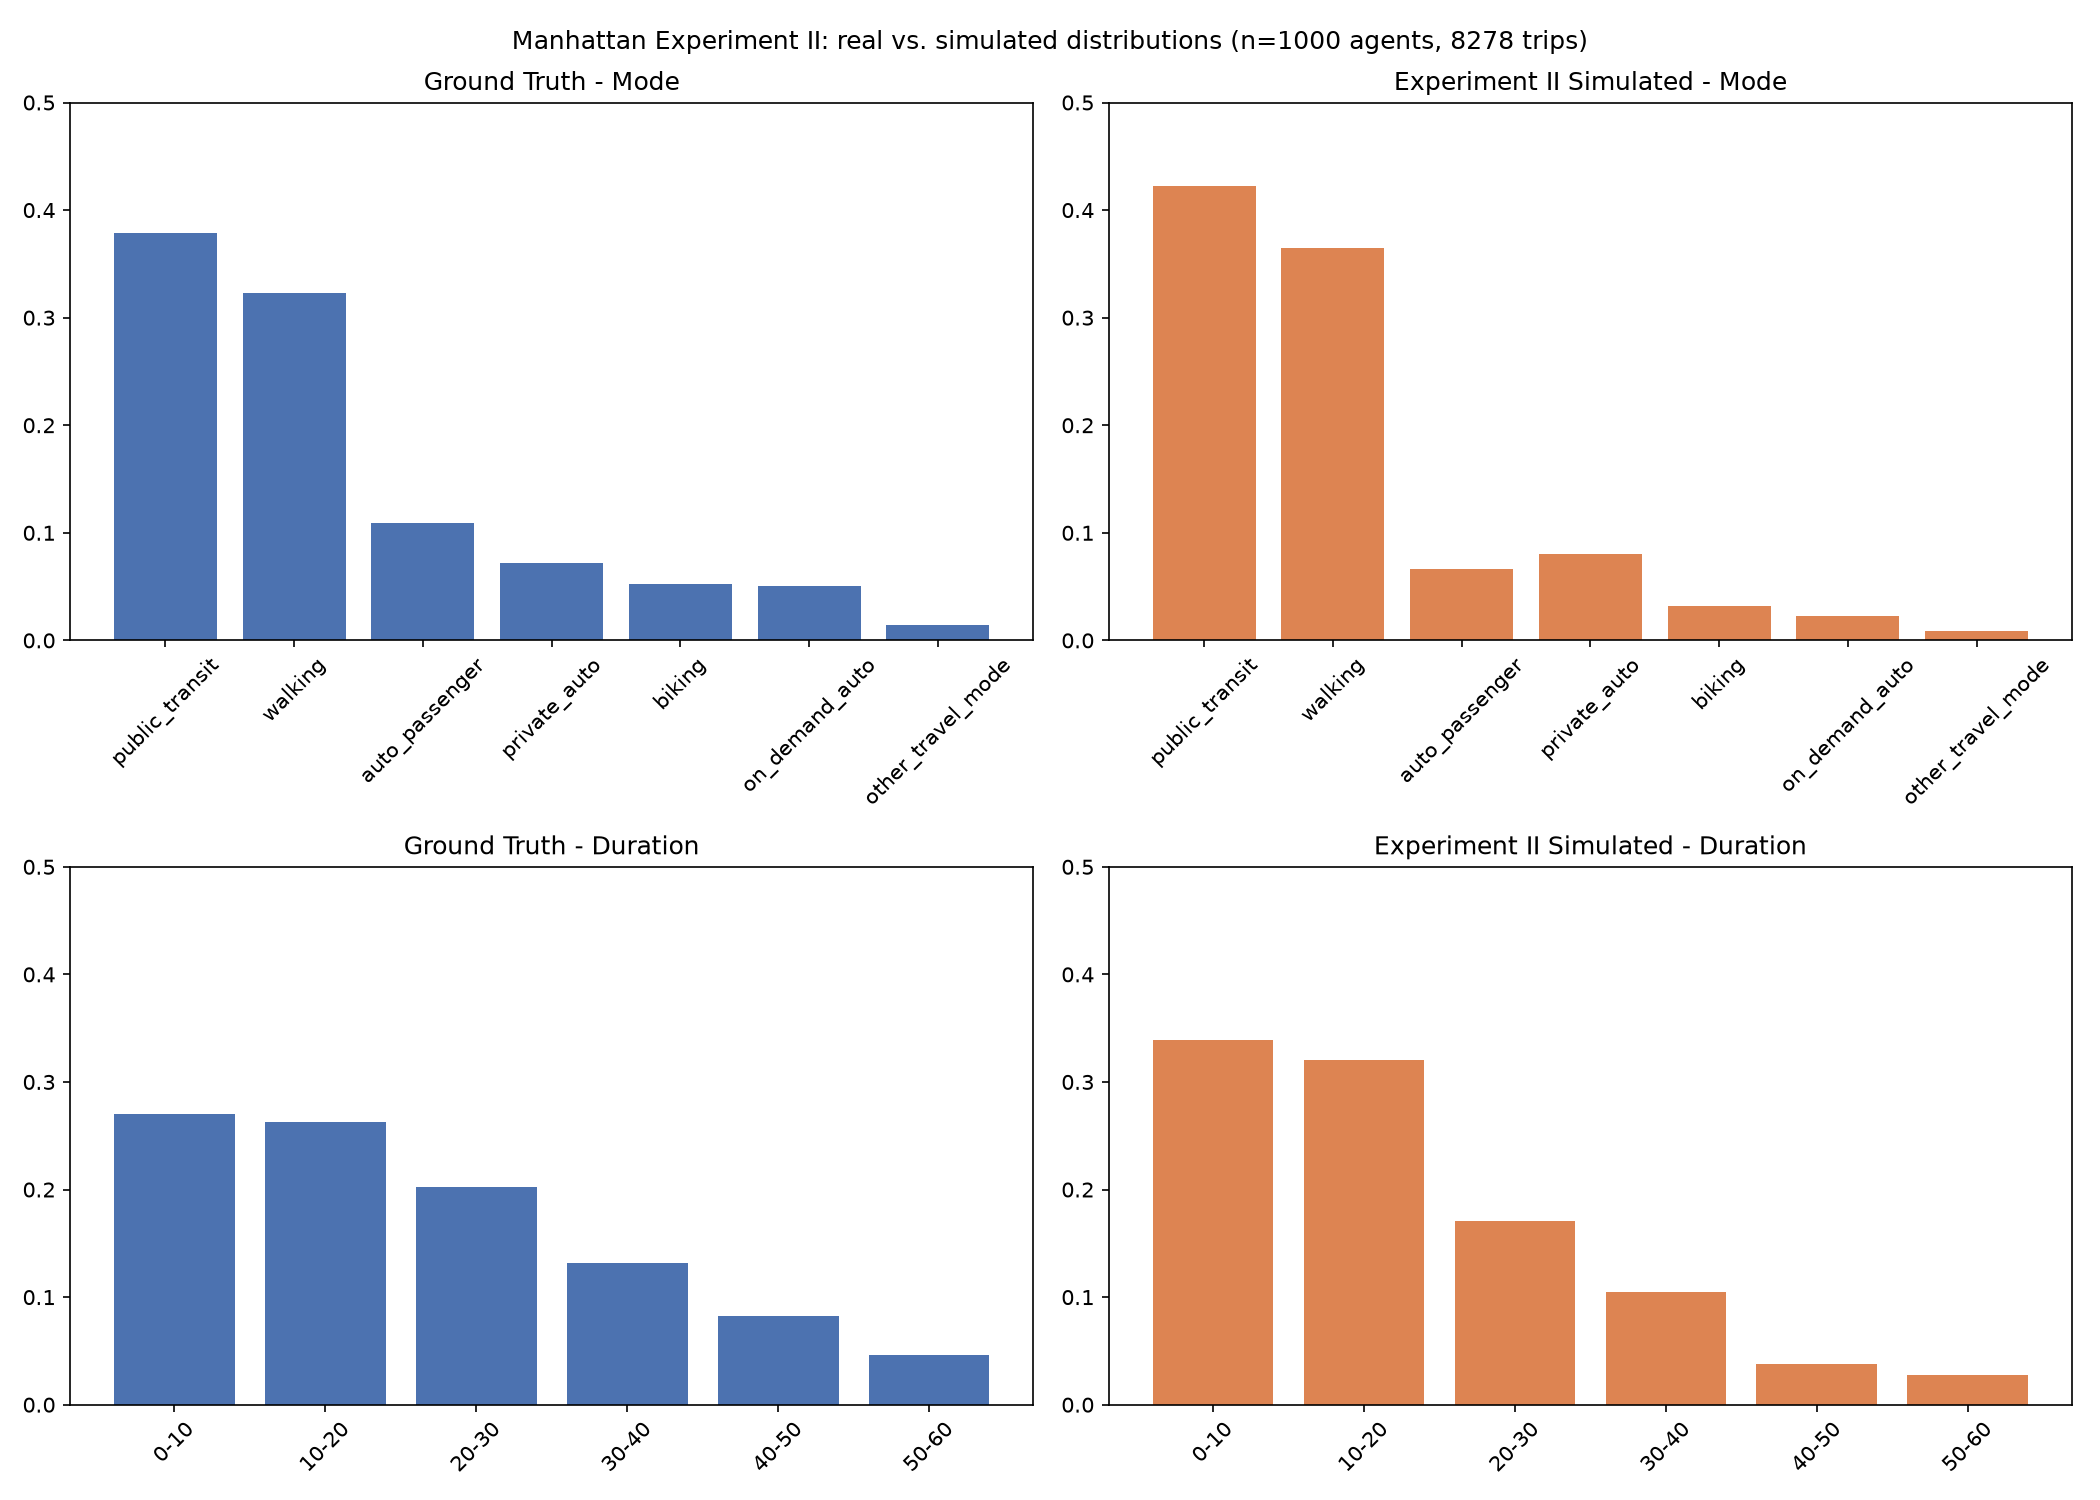

In [11]:
display(Image(filename=str(RESULTS / "exp2_mode_duration_comparison.png")))

### Demographics

In [12]:
demo = load("exp2_demographics_validation.json")
pd.DataFrame({k: {"KLD": v["kld"], "MAE": v["mae"]} for k, v in demo.items()}).T

,KLD,MAE
age_group,0.034303,0.028723
employment_status,0.037126,0.055264
education,0.128610,0.065263
household_size,0.005224,0.012529
income (coarse),0.000245,0.004754


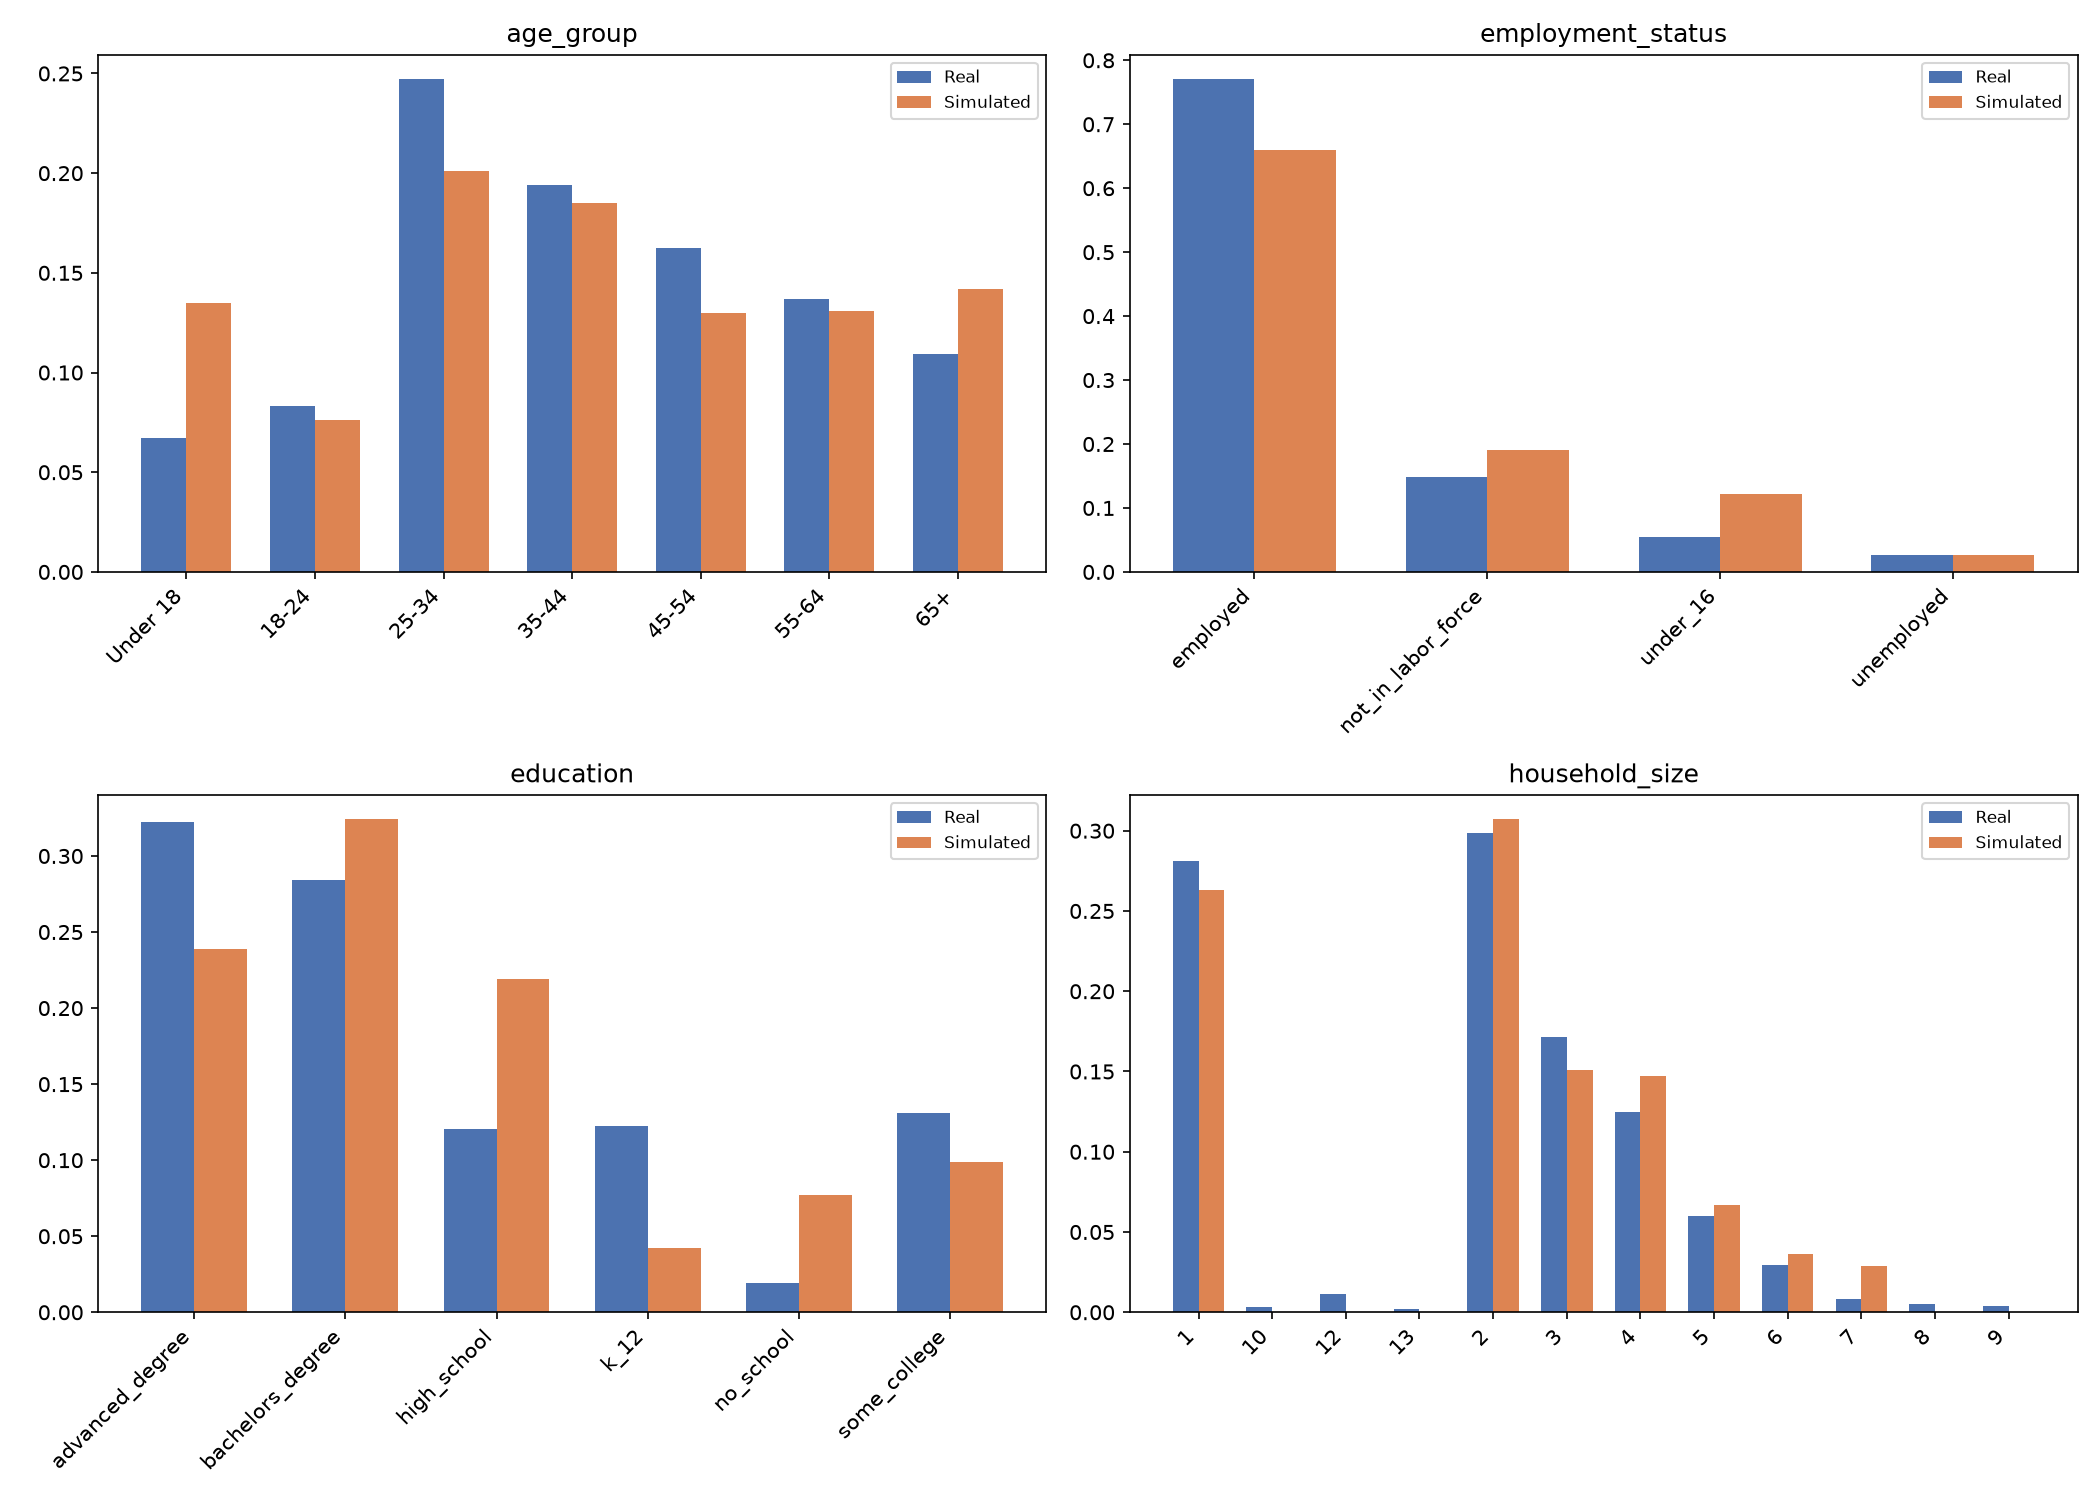

In [13]:
display(Image(filename=str(RESULTS / "exp2_demographics_comparison.png")))

### Trip purpose and timing

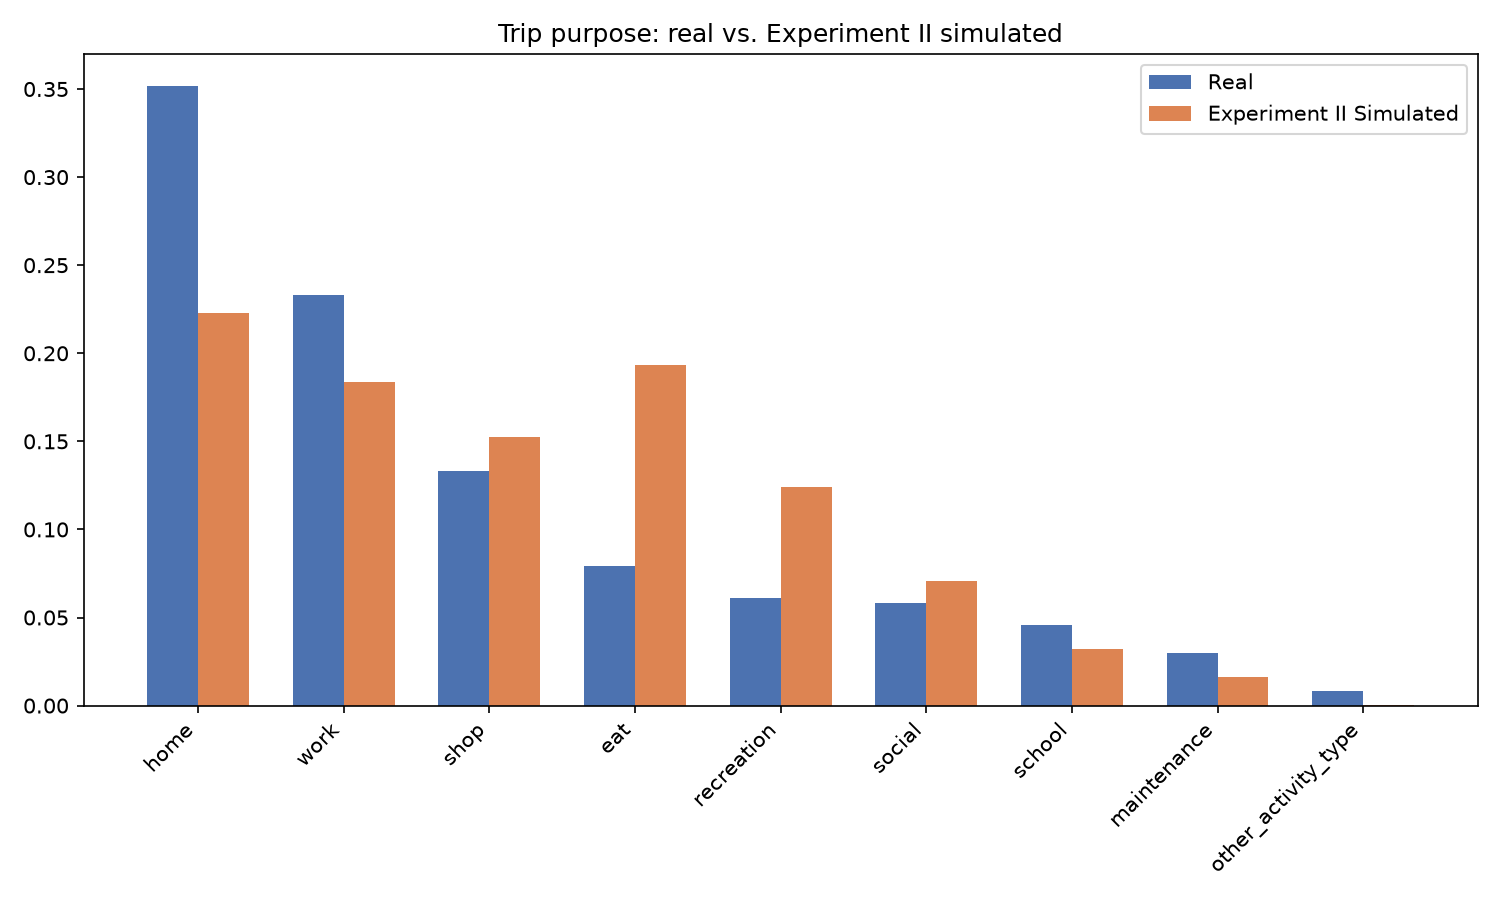

In [14]:
display(Image(filename=str(RESULTS / "exp2_trip_purpose_comparison.png")))

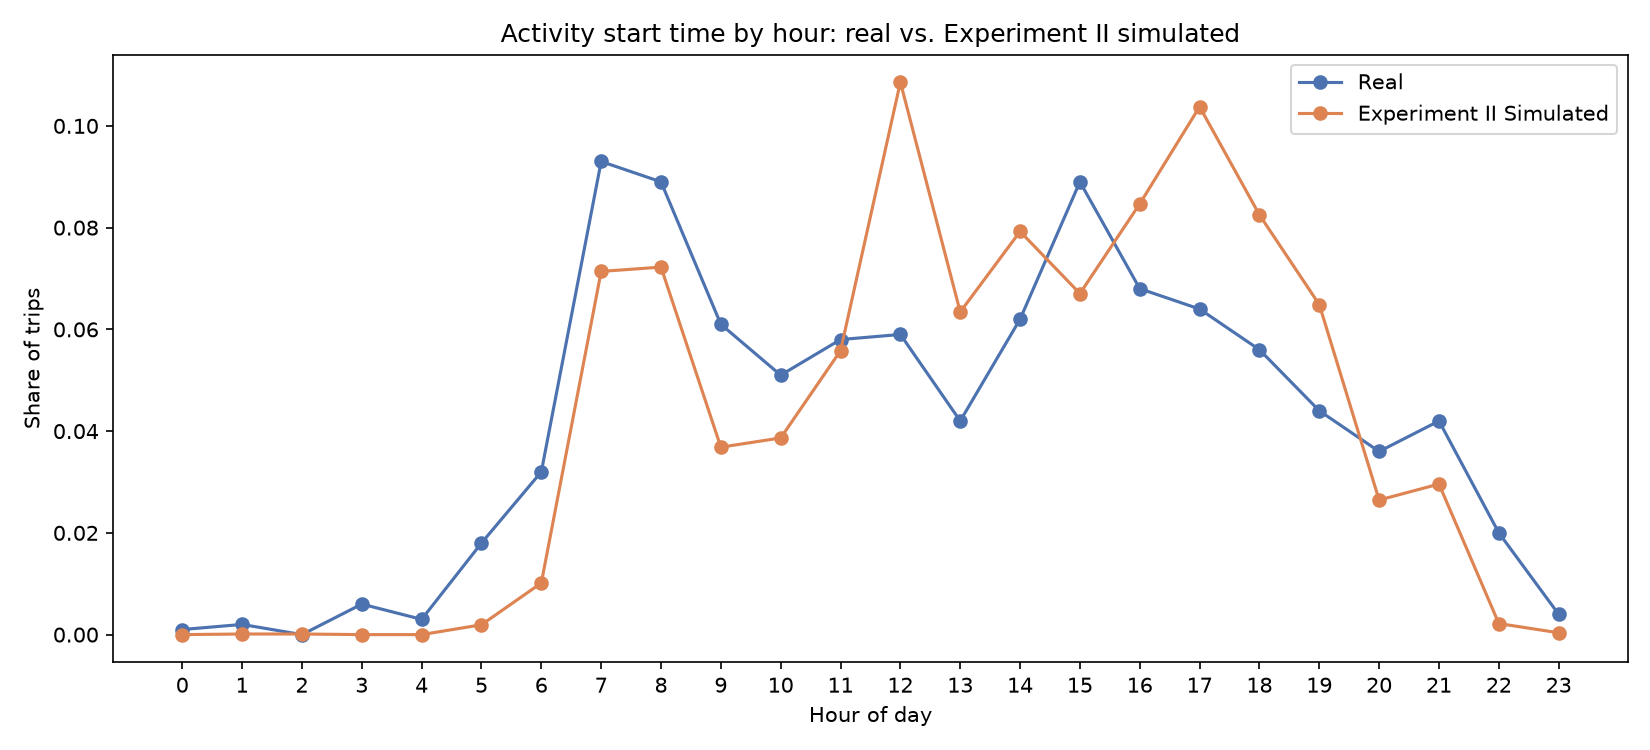

In [15]:
display(Image(filename=str(RESULTS / "exp2_starttime_by_hour.png")))

### Geography (home locations)

How closely synthetic agents' home census tracts match real population density.

In [16]:
geo = load("exp2_geography_validation.json")
display(Markdown(
    f"- **{geo['n_homes']}** homes, matched to **{geo['n_tracts_used']}/{geo['n_tracts_total']}** census tracts\n"
    f"- **KLD={geo['kld']:.3f}**, MAE={geo['mae']:.4f}\n"
    f"- avg population density, agent tracts vs. all tracts: "
    f"**{geo['avg_density_agent_tracts']:.0f}** vs. **{geo['avg_density_all_tracts']:.0f}**"
))

- **1000** homes, matched to **270/310** census tracts
- **KLD=0.898**, MAE=0.0013
- avg population density, agent tracts vs. all tracts: **6986** vs. **5309**

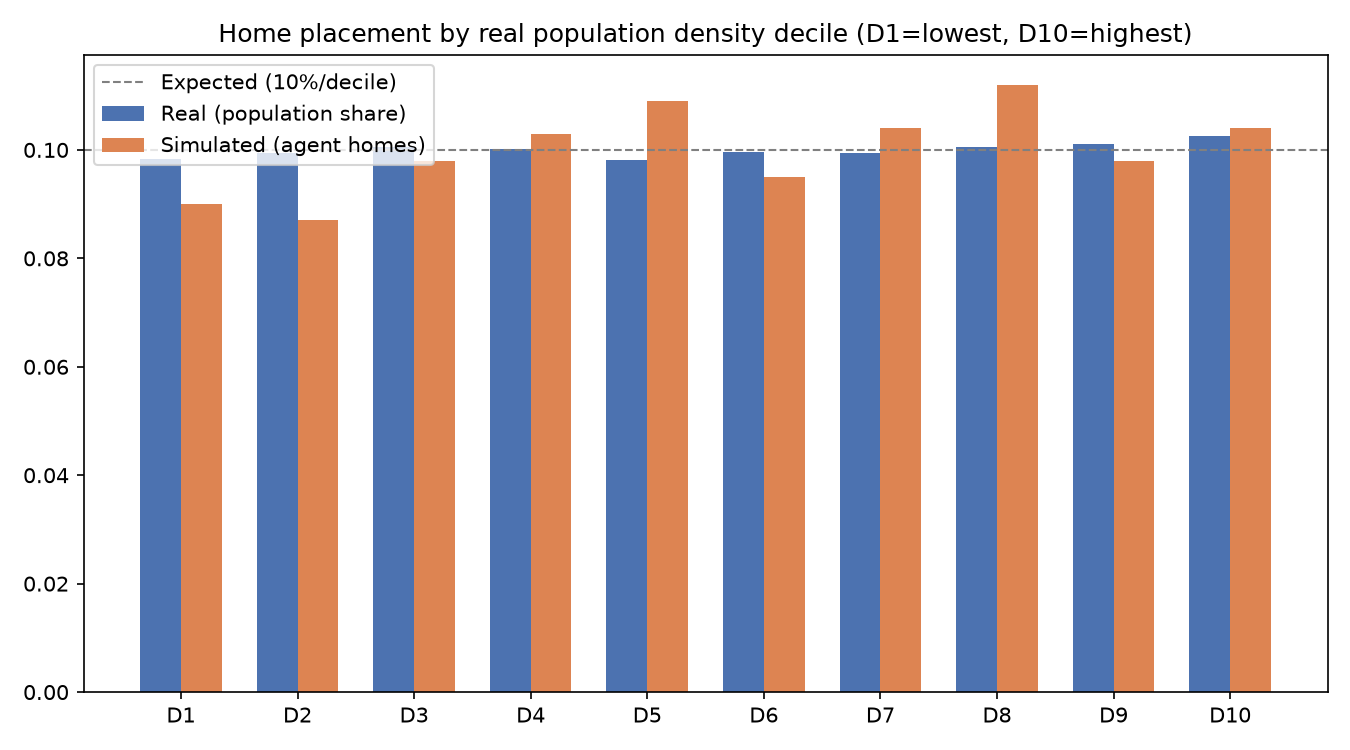

In [17]:
display(Image(filename=str(RESULTS / "exp2_geography_decile.png")))

### Points of interest

How much overlap there is between the POIs synthetic agents visit and the real Advan POI
catalog.

In [18]:
poi = load("exp2_poi_validation.json")
display(Markdown(
    f"- **{poi['n_stops_total']}** stops total ({poi['n_home_skipped']} home stops skipped)\n"
    f"- **{poi['n_distinct_sim_pois']}** distinct simulated POIs, **{poi['n_matched_both']}** also appear in the "
    f"real {poi['n_real_pois_catalog']}-POI catalog\n"
    f"- **KLD={poi['kld']:.3f}**"
))

- **8278** stops total (1846 home stops skipped)
- **3292** distinct simulated POIs, **3362** also appear in the real 38203-POI catalog
- **KLD=1.604**

### Schedule coherence

Sanity checks on the generated day-long schedules themselves, independent of comparison
against real data.

In [19]:
sched = load("exp2_schedule_coherence.json")
display(Markdown(
    f"- **{sched['n_agents_with_schedule']}/{sched['n_agents']}** agents got a valid schedule\n"
    f"- **{sched['avg_stops_per_agent']:.1f}** stops/agent on average "
    f"({sched['avg_home_stops_per_agent']:.1f} home, {sched['avg_non_home_stops_per_agent']:.1f} non-home)\n"
    f"- **{sched['pct_schedules_out_of_order']:.1%}** of schedules are chronologically out of order"
))

- **999/1000** agents got a valid schedule
- **8.3** stops/agent on average (1.8 home, 6.4 non-home)
- **1.4%** of schedules are chronologically out of order

### Traffic flow

Real Manhattan traffic includes residents, commuters, tourists, and commercial trips; this
simulation only models residents. The fair comparison is real-residents-only vs. simulated,
not simulated vs. everyone.

In [20]:
traf_res = load("exp2_traffic_residents_validation.json")
display(Markdown(
    f"Resident-only comparison, **n_edges={traf_res['n_edges_compared']}**:\n"
    f"- **KLD={traf_res['kld_resident_vs_resident']:.3f}**\n"
    f"- **Spearman rank correlation={traf_res['spearman_resident_vs_resident']:.3f}** "
    f"(p={traf_res['spearman_pvalue']:.2g})\n\n"
    f"For context, the scope-mismatched comparison (simulated residents vs. ALL real traffic):\n"
    f"- KLD={traf_res['kld_resident_sim_vs_everyone_real']:.3f}, "
    f"Spearman={traf_res['spearman_resident_sim_vs_everyone_real']:.3f}"
))

Resident-only comparison, **n_edges=7117**:
- **KLD=0.297**
- **Spearman rank correlation=0.787** (p=0)

For context, the scope-mismatched comparison (simulated residents vs. ALL real traffic):
- KLD=2.693, Spearman=0.180

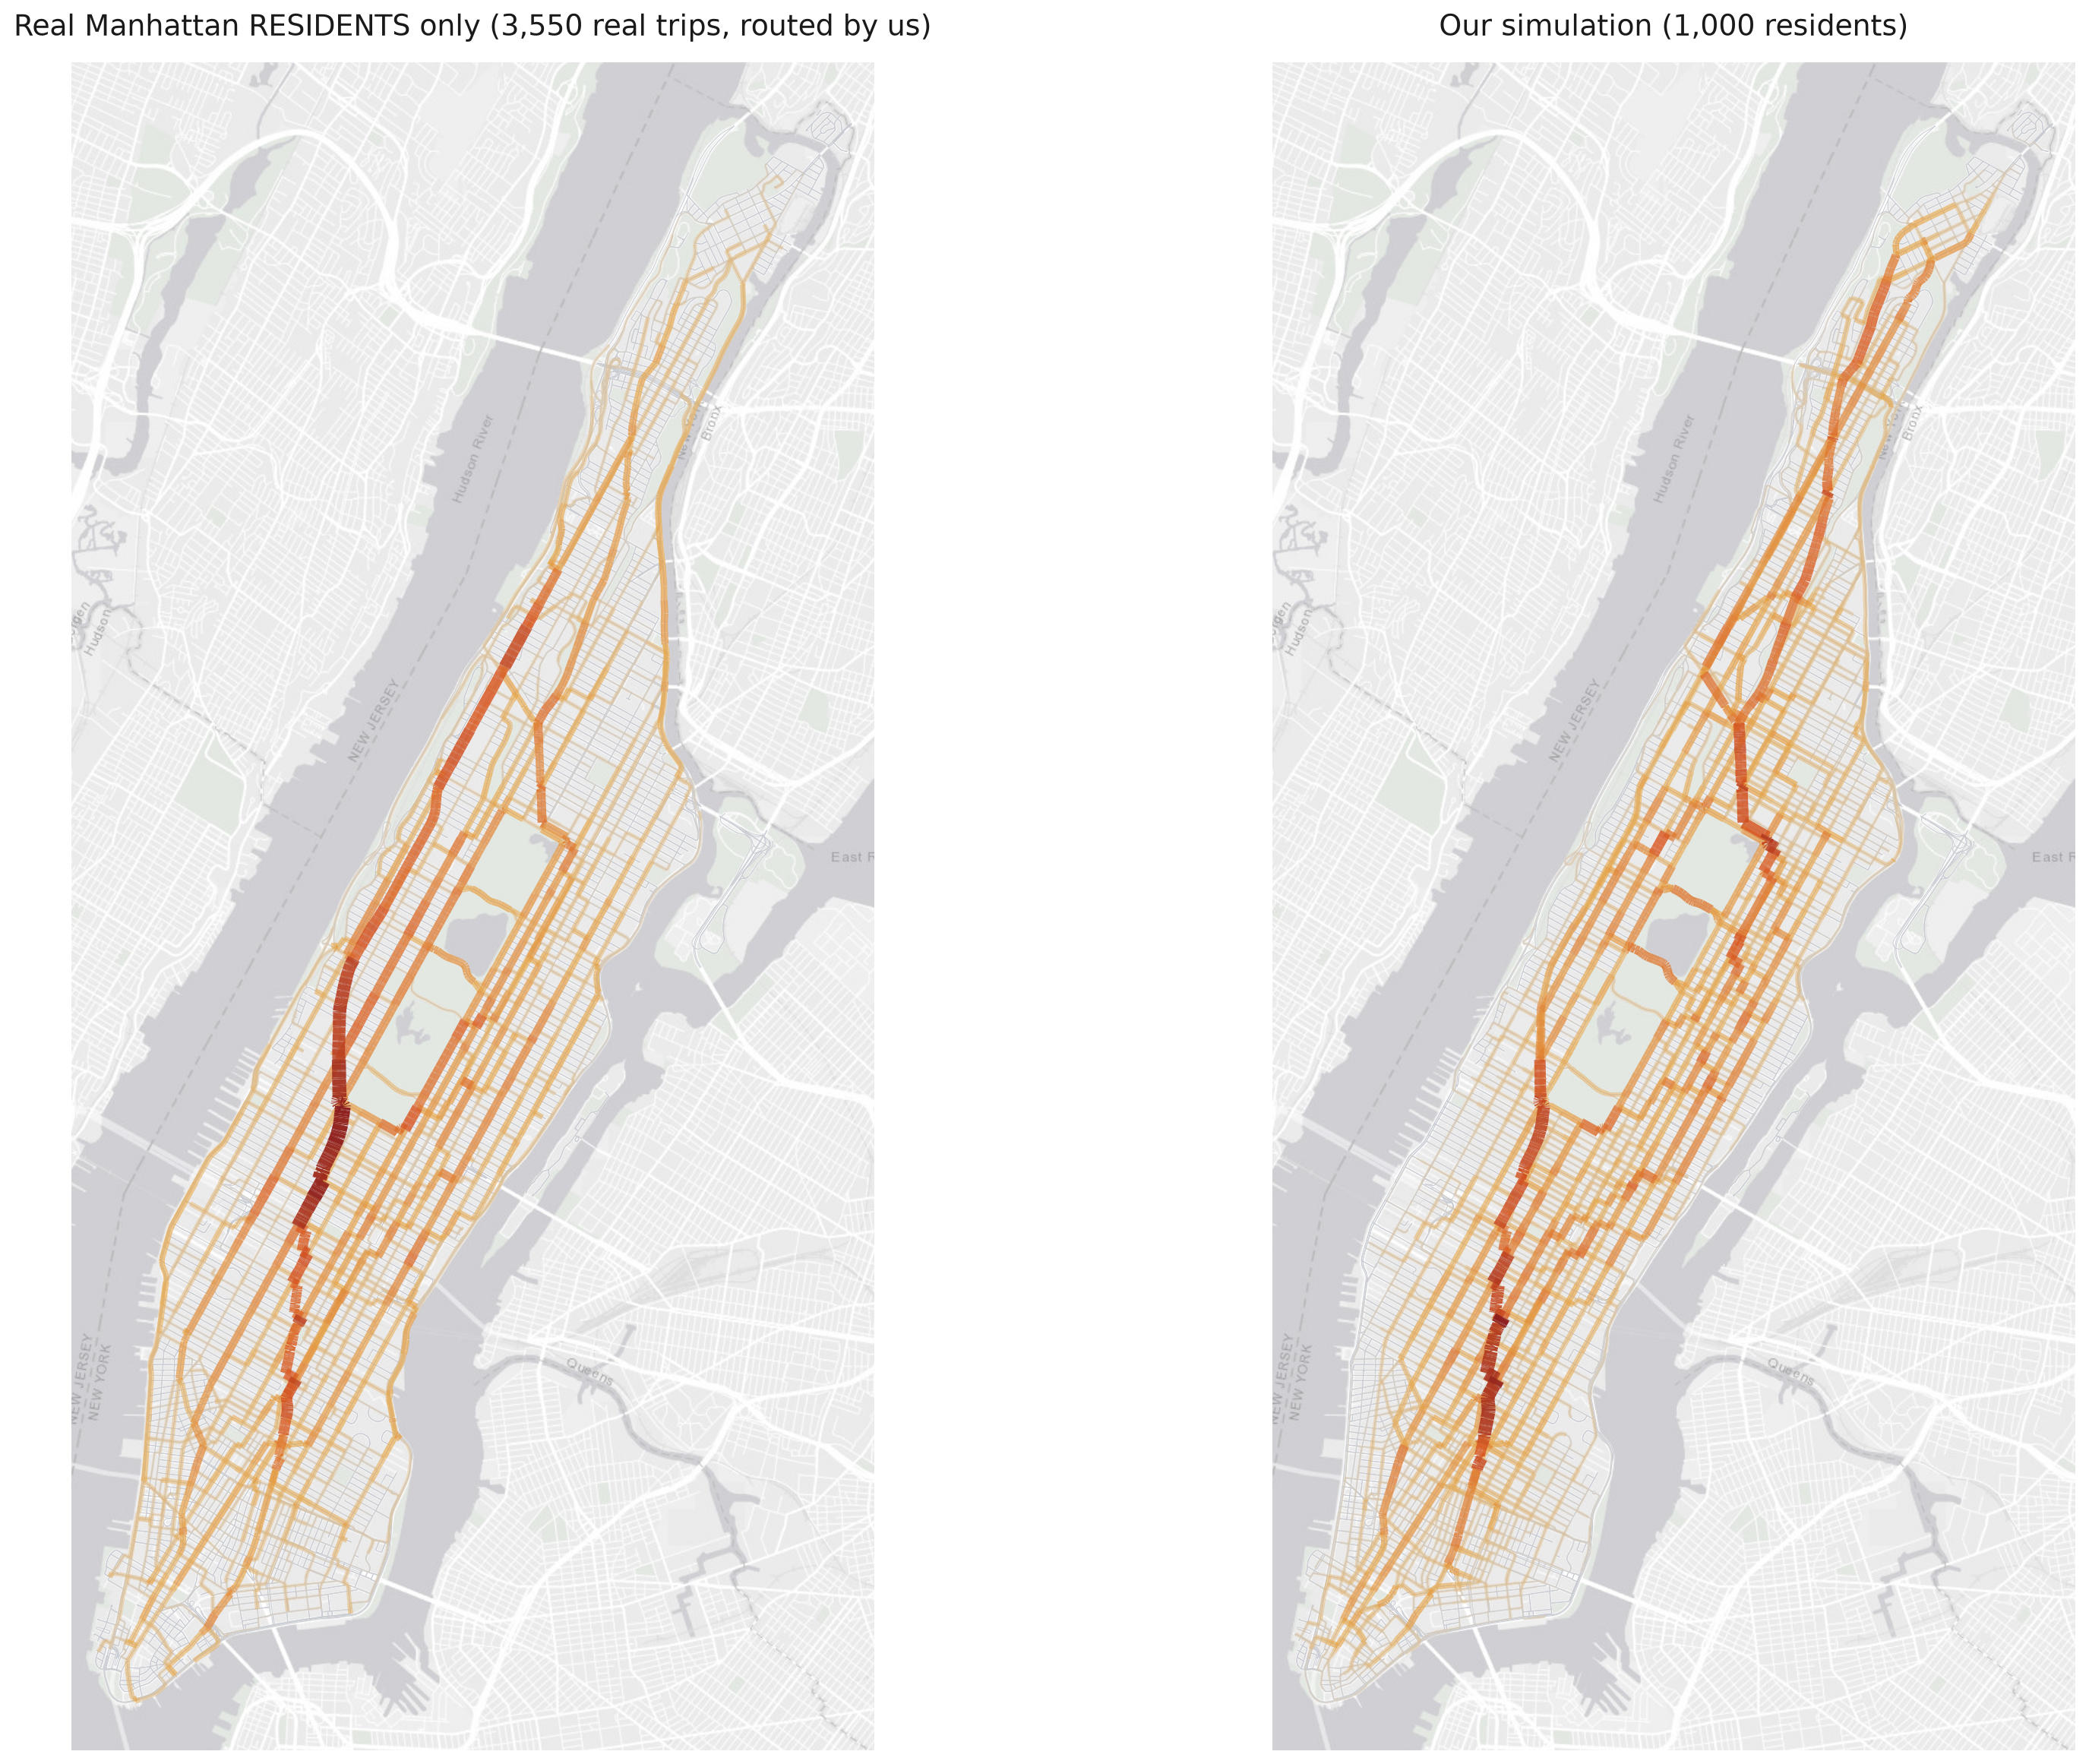

In [21]:
display(Image(filename=str(RESULTS / "exp2_traffic_map_residents_light.png")))

---
See the [README](../README.md) for the full methodology: data pipeline, bug fixes,
experiment configuration, and the methodological limitations documented but not fixed.